<a href="https://colab.research.google.com/github/markhamj300-coder/sketch_to_image/blob/main/sketch_to_image_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sketches to Image using Generative AI

**Sketch-to-image pipeline using Stable Diffusion 1.5 + ControlNet (Scribble)**

**Pipeline**
1. Installs dependencies and loads the pretrained models
2. Loads sketches
3. Converts sketches into ControlNet conditioning images
4. Generates images guided by the sketch and a text prompt
5. Runs experiments: different prompts/styles, conditioning strength, guidance scale, seeds
6. Compares against a *no-sketch* baseline to show how the sketch influences the result
7. (Optional) Launches a small Gradio UI


## 1. Installation


In [1]:
# Tested with: diffusers 0.30+, transformers 4.44+, torch 2.x
%pip install -q "diffusers>=0.30.0" "transformers>=4.44.0" "accelerate>=0.33.0" safetensors pillow matplotlib numpy gradio

## 2. Imports & configuration

In [2]:
import os, random, math, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps, ImageFilter

from diffusers import (
    StableDiffusionControlNetPipeline,
    ControlNetModel,
    UniPCMultistepScheduler,
)

# ---------------- Models (Hugging Face Hub IDs) ----------------
BASE_MODEL_ID       = "stable-diffusion-v1-5/stable-diffusion-v1-5"   # base text-to-image latent diffusion model
CONTROLNET_MODEL_ID = "lllyasviel/control_v11p_sd15_scribble"          # ControlNet 1.1 trained on scribble/sketch maps

# ---------------- Default generation settings ----------------
IMG_SIZE   = 512     # SD1.5 native resolution (use 384 for faster CPU tests)
STEPS      = 30      # denoising steps
GUIDANCE   = 7.5     # classifier-free guidance scale (text adherence)
CN_SCALE   = 1.0     # controlnet_conditioning_scale (sketch adherence)
SEED       = 42
NEGATIVE   = "lowres, blurry, deformed, bad anatomy, extra limbs, watermark, text, signature, cropped, jpeg artifacts"

# ---------------- Paths ----------------
SKETCH_DIR = Path("sketches");  SKETCH_DIR.mkdir(exist_ok=True)
OUT_DIR    = Path("outputs");   OUT_DIR.mkdir(exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DTYPE  = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"Device: {DEVICE} | dtype: {DTYPE} | torch {torch.__version__}")
if DEVICE == "cpu":
    print("⚠️ Running on CPU – consider IMG_SIZE=384 and STEPS=15 for a quick test.")

Device: cuda | dtype: torch.float16 | torch 2.14.1+cu130


### Load sketches (in `sketches/`)

Sketches found: ['desk_lamp', 'robot', 'tower']


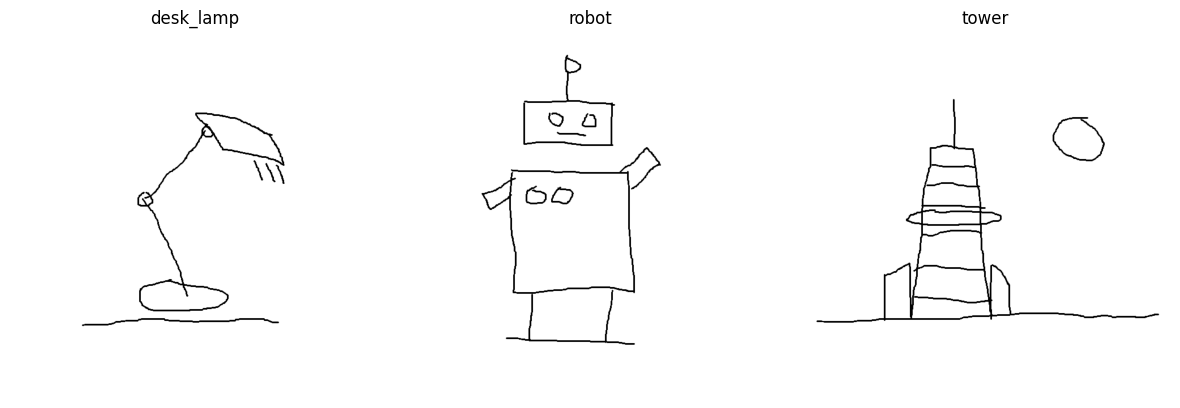

In [19]:
def load_sketches(folder=SKETCH_DIR):
    exts = {".png", ".jpg", ".jpeg", ".webp"}
    out = {}
    for p in sorted(folder.iterdir()):
        if p.suffix.lower() in exts:
            out[p.stem] = Image.open(p).convert("L")
    return out

sketches = load_sketches()
print("Sketches found:", list(sketches))

fig, axes = plt.subplots(1, len(sketches), figsize=(4*len(sketches), 4))
axes = np.atleast_1d(axes)
for ax, (n, im) in zip(axes, sketches.items()):
    ax.imshow(im, cmap="gray"); ax.set_title(n); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Preprocessing

The scribble ControlNet was trained on images where the strokes are white on a black background. Our sketches are the opposite so some preprocessing is needed:

1. Convert to grayscale and resize/pad to a square `IMG_SIZE × IMG_SIZE` (preserving the aspect ratio)
2. Apply auto-contrast + a threshold to get a clean binary stroke map (handles photographed paper sketches with uneven lighting)
3. Invert colour
4. Slightly dilate the strokes to make thin lines more visible to the network



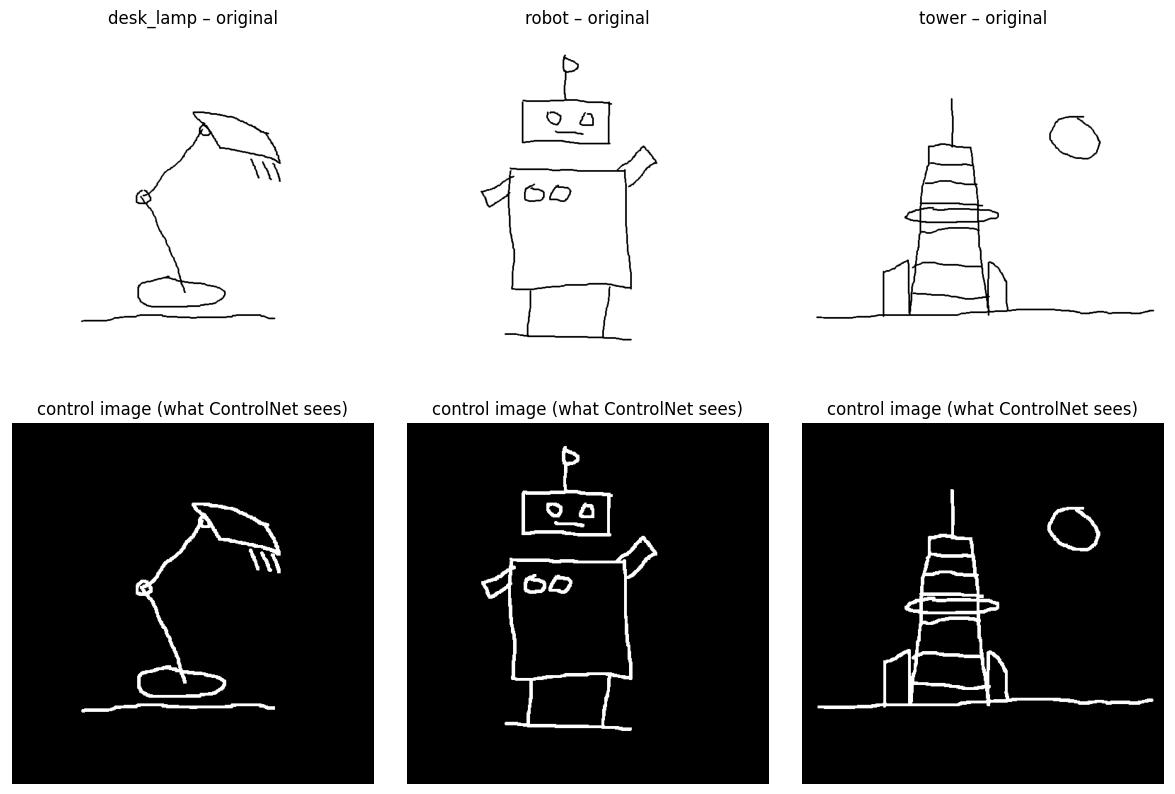

In [20]:
def prepare_control_image(sketch: Image.Image, size=IMG_SIZE, threshold=170, dilate=3) -> Image.Image:
    g = ImageOps.autocontrast(sketch.convert("L"))
    # letterbox to a square canvas (white background) without distorting the sketch
    g = ImageOps.pad(g, (size, size), color=255, method=Image.LANCZOS)
    # binarise: dark pixels = stroke
    bw = g.point(lambda v: 255 if v < threshold else 0)       # white strokes on black
    if dilate and dilate > 1:
        bw = bw.filter(ImageFilter.MaxFilter(dilate if dilate % 2 else dilate + 1))
    return bw.convert("RGB")

controls = {n: prepare_control_image(im) for n, im in sketches.items()}

fig, axes = plt.subplots(2, len(sketches), figsize=(4*len(sketches), 8))
for i, n in enumerate(sketches):
    axes[0, i].imshow(sketches[n], cmap="gray"); axes[0, i].set_title(f"{n} – original"); axes[0, i].axis("off")
    axes[1, i].imshow(controls[n]);               axes[1, i].set_title("control image (what ControlNet sees)"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

## 5. Load the pipeline



In [21]:
t0 = time.time()
controlnet = ControlNetModel.from_pretrained(CONTROLNET_MODEL_ID, torch_dtype=DTYPE)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    BASE_MODEL_ID, controlnet=controlnet, torch_dtype=DTYPE
)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)

if DEVICE == "cuda":
    # Lower VRAM use (fits ~6GB). Replace with pipe.to("cuda") if you have plenty of VRAM (faster).
    pipe.enable_model_cpu_offload()
    try:
        pipe.enable_xformers_memory_efficient_attention()
    except Exception:
        pass  # xformers is optional; PyTorch SDPA is used by default
else:
    pipe.to(DEVICE)
pipe.enable_attention_slicing()
print(f"Pipeline ready in {time.time()-t0:.1f}s")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Pipeline ready in 29.4s


## 6. Generation helper

In [17]:
def generate(sketch, prompt, negative=NEGATIVE, cn_scale=CN_SCALE, guidance=GUIDANCE,
             steps=STEPS, seed=SEED, size=IMG_SIZE, control_image=None):
    # Run sketch + prompt through the ControlNet-guided diffusion pipeline.
    ctrl = control_image if control_image is not None else prepare_control_image(sketch, size)
    gen = torch.Generator(device="cpu").manual_seed(seed)   # reproducible noise
    result = pipe(
        prompt=prompt,
        negative_prompt=negative,
        image=ctrl,
        num_inference_steps=steps,
        guidance_scale=guidance,
        controlnet_conditioning_scale=cn_scale,
        generator=gen,
    )
    return result.images[0]

def show_row(images, titles, figsize_per=4, suptitle=None, save_as=None):
    fig, axes = plt.subplots(1, len(images), figsize=(figsize_per*len(images), figsize_per+0.6))
    axes = np.atleast_1d(axes)
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im, cmap="gray"); ax.set_title(t, fontsize=9); ax.axis("off")
    if suptitle: fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    if save_as: fig.savefig(OUT_DIR / save_as, dpi=130, bbox_inches="tight")
    plt.show()

## 7. First test
Check that everything works before running the full experiments.

  0%|          | 0/30 [00:00<?, ?it/s]

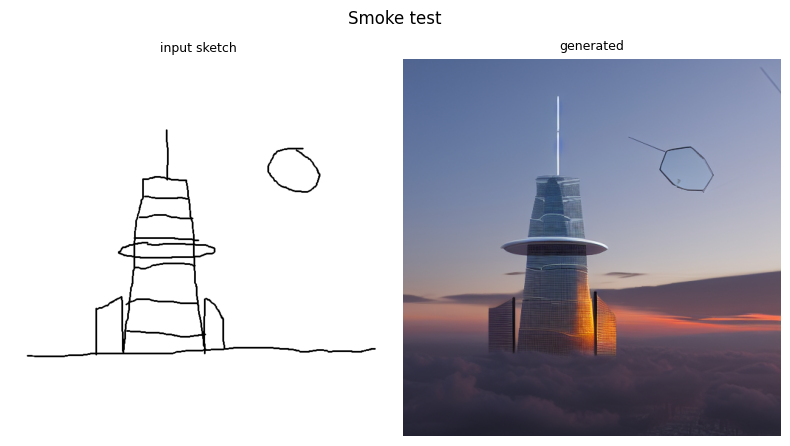

In [22]:
test_img = generate(sketches["tower"],
    "a futuristic glass skyscraper at sunset, cinematic lighting, highly detailed architectural photography, 8k")
show_row([sketches["tower"], test_img], ["input sketch", "generated"], suptitle="Smoke test")

## 8. Experiment A: three sketches with prompts


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

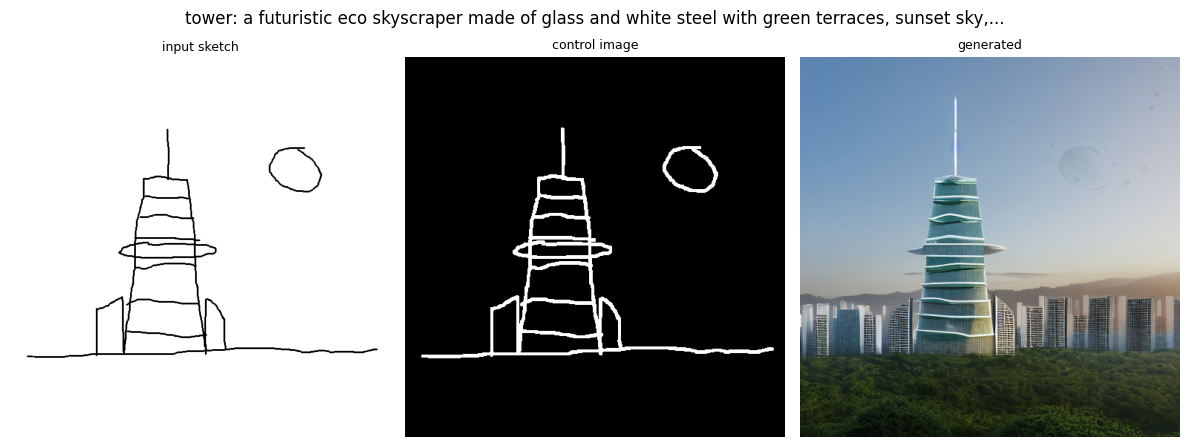

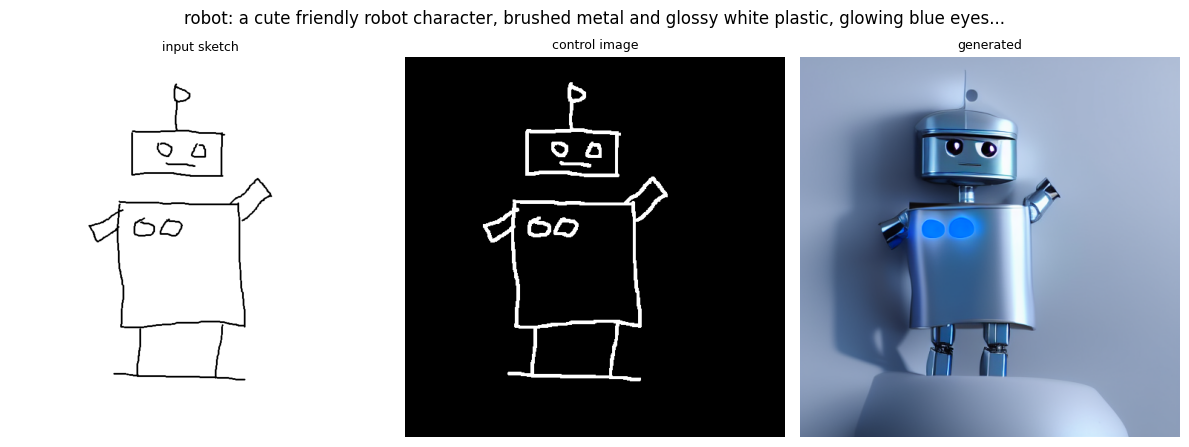

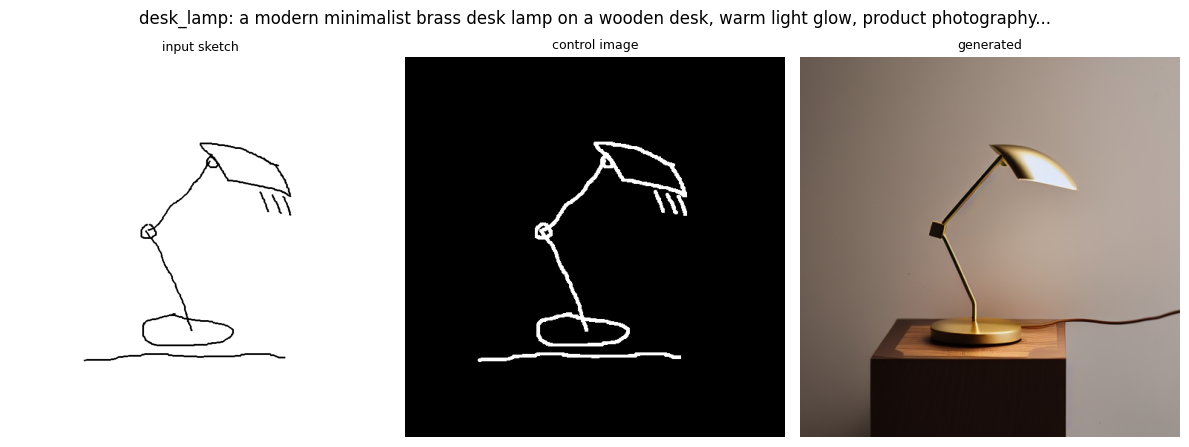

In [23]:
main_prompts = {
    "tower": "a futuristic eco skyscraper made of glass and white steel with green terraces, sunset sky, "
             "cinematic lighting, architectural photography, ultra detailed, 8k",
    "robot": "a cute friendly robot character, brushed metal and glossy white plastic, glowing blue eyes, "
             "soft studio lighting, pixar style 3d render, highly detailed",
    "desk_lamp": "a modern minimalist brass desk lamp on a wooden desk, warm light glow, "
                 "product photography, shallow depth of field, studio lighting, highly detailed",
}

results_main = {}
for name, prompt in main_prompts.items():
    if name not in sketches:
        continue
    out = generate(sketches[name], prompt, seed=SEED)
    results_main[name] = out
    out.save(OUT_DIR / f"A_{name}.png")

for name, out in results_main.items():
    show_row([sketches[name], controls[name], out],
             ["input sketch", "control image", "generated"],
             suptitle=f"{name}: {main_prompts[name][:90]}...", save_as=f"A_{name}_comparison.png")

## 9. Experiment B: same sketch with different prompts

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

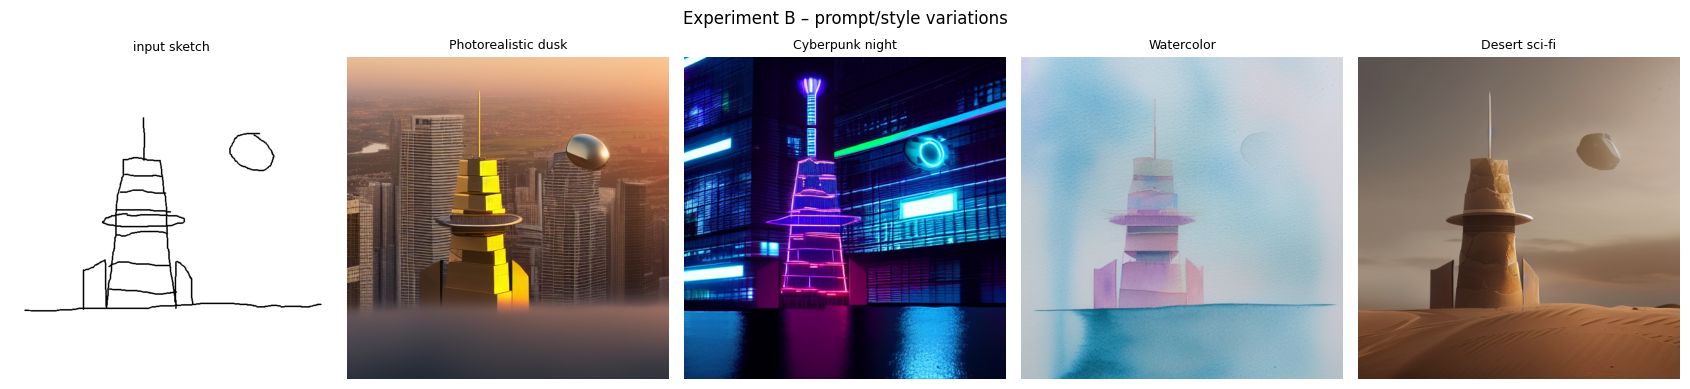

In [24]:
style_prompts = {
    "Photorealistic dusk": "futuristic skyscraper, photorealistic, golden hour, city skyline, 8k architectural photo",
    "Cyberpunk night":     "futuristic cyberpunk tower, neon lights, rainy night, reflections, blade runner atmosphere",
    "Watercolor":          "futuristic tower, watercolor painting, soft pastel colors, paper texture, artistic illustration",
    "Desert sci-fi":       "futuristic sandstone tower in a desert, dune landscape, dramatic sky, concept art, matte painting",
}
imgs, titles = [], []
for title, p in style_prompts.items():
    imgs.append(generate(sketches["tower"], p, seed=SEED)); titles.append(title)
    imgs[-1].save(OUT_DIR / f"B_tower_{title.split()[0].lower()}.png")
show_row([sketches["tower"]] + imgs, ["input sketch"] + titles, figsize_per=3.4,
         suptitle="Experiment B – prompt/style variations", save_as="B_styles.png")

## 10. Experiment C: testing sketch adherence (`controlnet_conditioning_scale`)

Varying `controlnet_conditioning_scale` changes model's faithfulness to the sketch:
* `0.0` → ControlNet disabled: the sketch has no influence
* `0.5` → loose interpretation
* `1.0` → default, faithful to sketch
* `1.5` → very strict

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

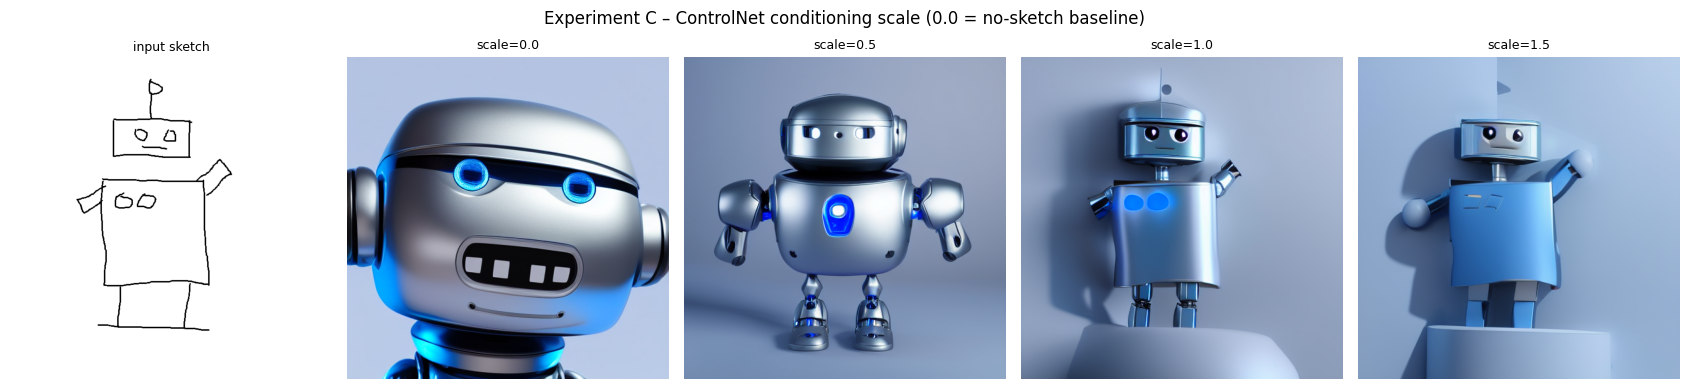

In [25]:
prompt_c = main_prompts["robot"]
scales = [0.0, 0.5, 1.0, 1.5]
imgs = [generate(sketches["robot"], prompt_c, cn_scale=s, seed=SEED) for s in scales]
show_row([sketches["robot"]] + imgs, ["input sketch"] + [f"scale={s}" for s in scales], figsize_per=3.4,
         suptitle="Experiment C – ControlNet conditioning scale (0.0 = no-sketch baseline)", save_as="C_conditioning_scale.png")

## 11. Experiment D: guidance scale & random seed

* **Guidance scale (CFG):** higher = follows the text more strongly, lower = more freedom/softer images
* **Seed:** different initial noise → different interpretations of the same sketch

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

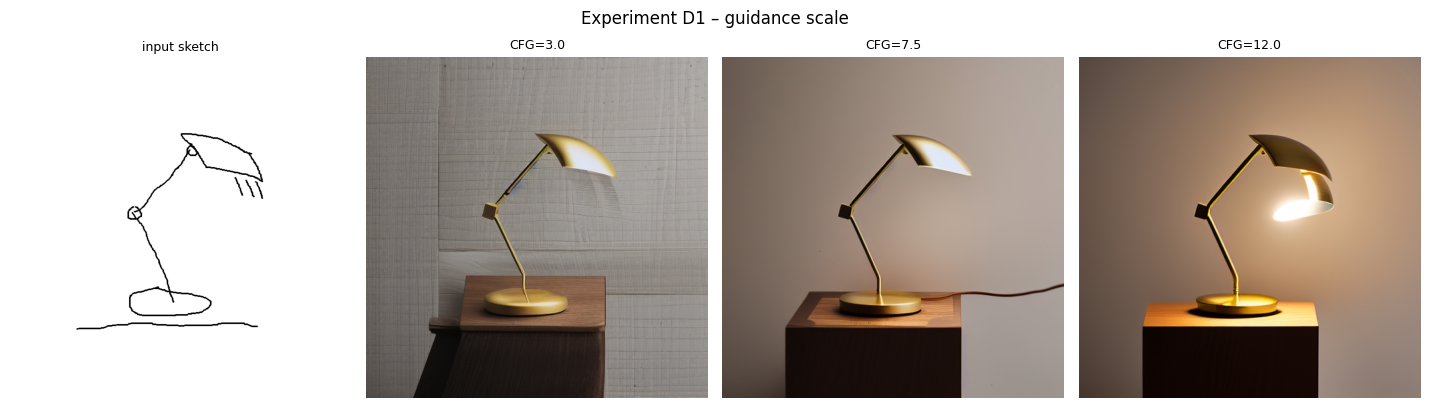

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

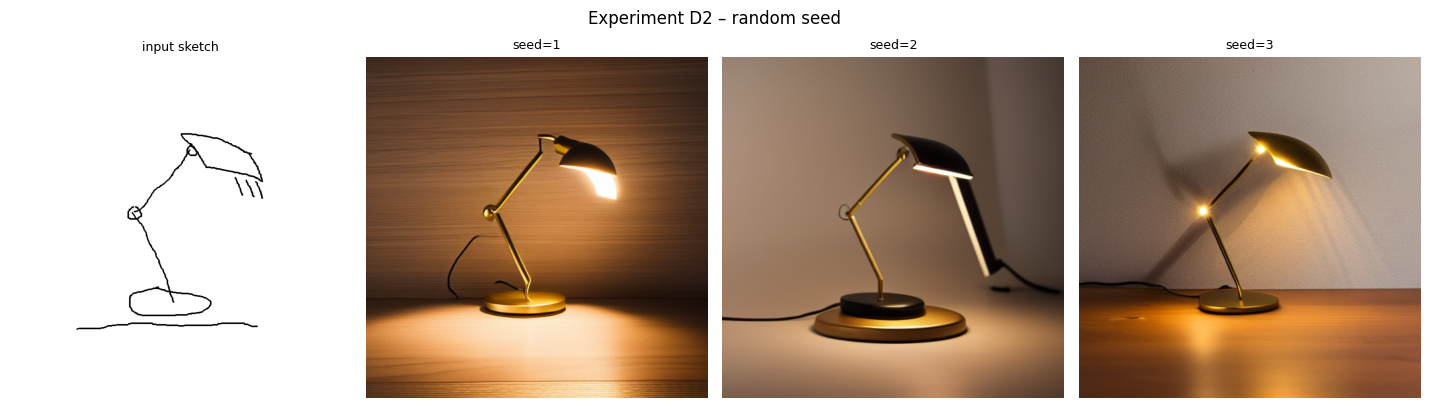

In [26]:
prompt_d = main_prompts["desk_lamp"]
guidances = [3.0, 7.5, 12.0]
imgs = [generate(sketches["desk_lamp"], prompt_d, guidance=g, seed=SEED) for g in guidances]
show_row([sketches["desk_lamp"]] + imgs, ["input sketch"] + [f"CFG={g}" for g in guidances], figsize_per=3.6,
         suptitle="Experiment D1 – guidance scale", save_as="D1_guidance.png")

seeds = [1, 2, 3]
imgs = [generate(sketches["desk_lamp"], prompt_d, seed=s) for s in seeds]
show_row([sketches["desk_lamp"]] + imgs, ["input sketch"] + [f"seed={s}" for s in seeds], figsize_per=3.6,
         suptitle="Experiment D2 – random seed", save_as="D2_seeds.png")

## 13. Summary: main results

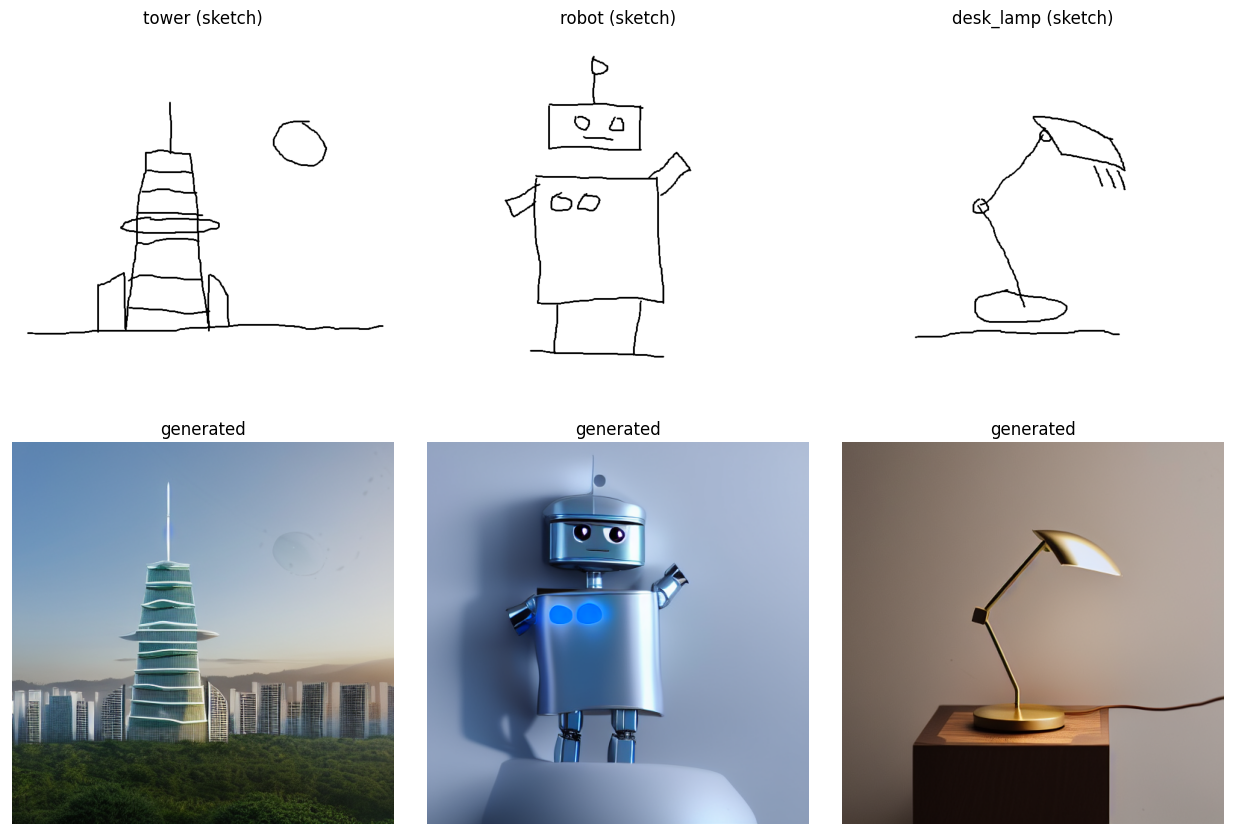

Outputs saved in: /content/outputs -> ['A_desk_lamp.png', 'A_desk_lamp_comparison.png', 'A_robot.png', 'A_robot_comparison.png', 'A_tower.png', 'A_tower_comparison.png', 'B_styles.png', 'B_tower_cyberpunk.png', 'B_tower_desert.png', 'B_tower_photorealistic.png', 'B_tower_watercolor.png', 'C_conditioning_scale.png', 'D1_guidance.png', 'D2_seeds.png', 'E_custom.png', 'summary_contact_sheet.png']


In [28]:
names = [n for n in main_prompts if n in results_main]
fig, axes = plt.subplots(2, len(names), figsize=(4.2*len(names), 8.4))
axes = np.array(axes).reshape(2, len(names))
for i, n in enumerate(names):
    axes[0, i].imshow(sketches[n], cmap="gray"); axes[0, i].set_title(f"{n} (sketch)"); axes[0, i].axis("off")
    axes[1, i].imshow(results_main[n]);          axes[1, i].set_title("generated");       axes[1, i].axis("off")
plt.tight_layout(); fig.savefig(OUT_DIR / "summary_contact_sheet.png", dpi=130, bbox_inches="tight"); plt.show()
print("Outputs saved in:", OUT_DIR.resolve(), "->", sorted(p.name for p in OUT_DIR.iterdir()))